In [1]:
import sys, torch
print(sys.executable)
print(torch.__version__, torch.cuda.is_available())

d:\thesis\.venv\Scripts\python.exe
2.6.0+cu124 True


In [5]:
import os
import pandas as pd

os.chdir(r"D:\thesis")

df = pd.read_csv("data/raw/HAM10000/HAM10000_metadata.csv")

print("images :", len(df))
print("lesions:", df.lesion_id.nunique())
print("\nIMAGES per class:")
print(df.dx.value_counts())

les = df.groupby("lesion_id").agg(dx=("dx", "first")).reset_index()
print("\nUNIQUE LESIONS per class:")
print(les.dx.value_counts())
print("\nApprox TEST lesions at 15%:")
print((les.dx.value_counts() * 0.15).round(0).astype(int))

images : 10015
lesions: 7470

IMAGES per class:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

UNIQUE LESIONS per class:
dx
nv       5403
bkl       727
mel       614
bcc       327
akiec     228
vasc       98
df         73
Name: count, dtype: int64

Approx TEST lesions at 15%:
dx
nv       810
bkl      109
mel       92
bcc       49
akiec     34
vasc      15
df        11
Name: count, dtype: int64


In [6]:
from src.split import lesion_level_split, check_split

splits = lesion_level_split(df, seed=42)
check_split(splits, df)

for name, part in splits.items():
    print(f"{name:5s}  images={len(part):5d}  lesions={part.lesion_id.nunique():5d}")

All four leakage checks passed.
train  images= 6981  lesions= 5229
val    images= 1532  lesions= 1120
test   images= 1502  lesions= 1121


In [7]:
import pandas as pd

prop = pd.DataFrame({
    name: part.dx.value_counts(normalize=True) * 100
    for name, part in splits.items()
}).round(2)

prop["max_gap"] = (prop.max(axis=1) - prop.min(axis=1)).round(2)
print(prop.sort_values("train", ascending=False))
print("\nLargest gap between partitions:", prop["max_gap"].max(), "percentage points")

       train    val   test  max_gap
dx                                 
nv     67.08  66.45  66.84     0.63
mel    11.07  11.29  11.12     0.22
bkl    11.06  10.44  11.12     0.68
bcc     5.17   5.35   4.73     0.62
akiec   3.18   3.46   3.46     0.28
vasc    1.42   1.44   1.40     0.04
df      1.02   1.57   1.33     0.55

Largest gap between partitions: 0.68 percentage points


In [8]:
aug = ["mel", "bcc", "akiec", "vasc", "df"]
tr = splits["train"]

t = pd.DataFrame({
    "train_images":  tr.dx.value_counts()[aug],
    "train_lesions": tr.groupby("dx").lesion_id.nunique()[aug],
})
t["synthetic_needed"] = (1000 - t.train_images).clip(lower=0)
t["synth_per_real"] = (t.synthetic_needed / t.train_images).round(2)
print(t)

       train_images  train_lesions  synthetic_needed  synth_per_real
dx                                                                  
mel             773            430               227            0.29
bcc             361            229               639            1.77
akiec           222            159               778            3.50
vasc             99             69               901            9.10
df               71             51               929           13.08


In [9]:
counts = pd.DataFrame({n: p.dx.value_counts() for n, p in splits.items()})
counts["total"] = counts.sum(axis=1)
print(counts)
print()
print((counts[["train","val","test"]].div(counts["total"], axis=0) * 100).round(1))

       train   val  test  total
dx                             
akiec    222    53    52    327
bcc      361    82    71    514
bkl      772   160   167   1099
df        71    24    20    115
mel      773   173   167   1113
nv      4683  1018  1004   6705
vasc      99    22    21    142

       train   val  test
dx                      
akiec   67.9  16.2  15.9
bcc     70.2  16.0  13.8
bkl     70.2  14.6  15.2
df      61.7  20.9  17.4
mel     69.5  15.5  15.0
nv      69.8  15.2  15.0
vasc    69.7  15.5  14.8


In [10]:
import pandas as pd
from src.split import lesion_level_split, check_split

df = pd.read_csv("data/raw/HAM10000/HAM10000_metadata.csv")
splits = lesion_level_split(df, seed=42)
check_split(splits, df)

for name, part in splits.items():
    print(f"{name:5s}  images={len(part):5d}  lesions={part.lesion_id.nunique():5d}")

All four leakage checks passed.
train  images= 6981  lesions= 5229
val    images= 1532  lesions= 1120
test   images= 1502  lesions= 1121


In [11]:
from pathlib import Path

Path("data/splits").mkdir(parents=True, exist_ok=True)

for name, part in splits.items():
    out = f"data/splits/{name}.csv"
    part.to_csv(out, index=False)
    print(f"saved {out}  ({len(part)} rows)")

saved data/splits/train.csv  (6981 rows)
saved data/splits/val.csv  (1532 rows)
saved data/splits/test.csv  (1502 rows)


In [12]:
tr = pd.read_csv("data/splits/train.csv")
va = pd.read_csv("data/splits/val.csv")
te = pd.read_csv("data/splits/test.csv")

# 1. Leakage check, saved files par
assert not (set(tr.lesion_id) & set(te.lesion_id)), "LEAK train/test"
assert not (set(tr.lesion_id) & set(va.lesion_id)), "LEAK train/val"
assert not (set(va.lesion_id) & set(te.lesion_id)), "LEAK val/test"
assert len(tr) + len(va) + len(te) == 10015, "images lost"

# 2. Synthetic column kahin hai to nahi
for name, part in [("train", tr), ("val", va), ("test", te)]:
    assert "synthetic" not in part.columns, f"{name} has a synthetic column"

print("Saved splits verified: no leakage, no images lost, no synthetic rows.\n")
print(pd.DataFrame({"train": tr.dx.value_counts(),
                    "val": va.dx.value_counts(),
                    "test": te.dx.value_counts()}))

Saved splits verified: no leakage, no images lost, no synthetic rows.

       train   val  test
dx                      
akiec    222    53    52
bcc      361    82    71
bkl      772   160   167
df        71    24    20
mel      773   173   167
nv      4683  1018  1004
vasc      99    22    21


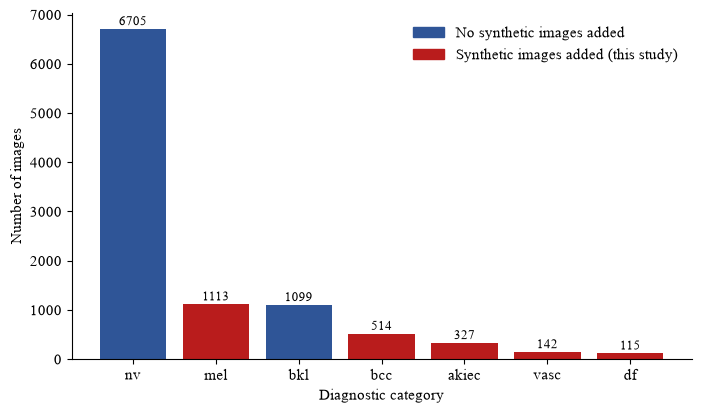

In [15]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 11,
    "savefig.dpi": 300,
    "figure.dpi": 100,
    "savefig.bbox": "tight",
})

Path("results/figures").mkdir(parents=True, exist_ok=True)

aug = ["mel", "bcc", "akiec", "vasc", "df"]
counts = df.dx.value_counts()

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#B91C1C" if c in aug else "#2F5597" for c in counts.index]
ax.bar(counts.index, counts.values, color=colors)

for i, v in enumerate(counts.values):
    ax.text(i, v + 80, str(v), ha="center", fontsize=9)

ax.set_xlabel("Diagnostic category")
ax.set_ylabel("Number of images")
ax.spines[["top", "right"]].set_visible(False)

import matplotlib.patches as mpatches
ax.legend(handles=[
    mpatches.Patch(color="#2F5597", label="No synthetic images added"),
    mpatches.Patch(color="#B91C1C", label="Synthetic images added (this study)"),
], frameon=False)

plt.savefig("results/figures/fig01_class_distribution.png")
plt.show()

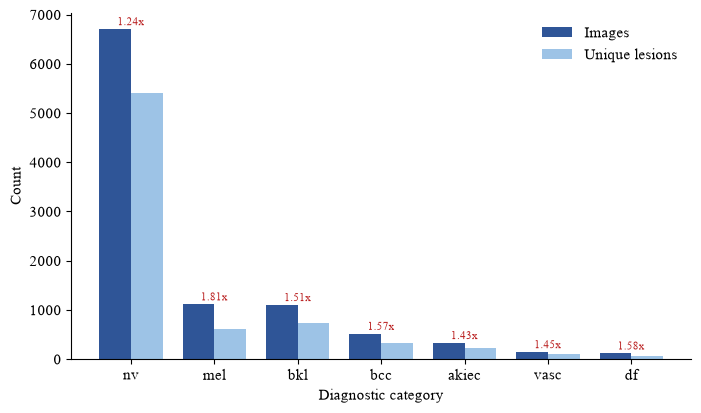

In [16]:
import numpy as np

les = df.groupby("lesion_id").agg(dx=("dx", "first")).reset_index()
order = counts.index                      # same order as Figure 1
img_n = counts[order].values
les_n = les.dx.value_counts()[order].values

x = np.arange(len(order))
w = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - w/2, img_n, w, label="Images", color="#2F5597")
ax.bar(x + w/2, les_n, w, label="Unique lesions", color="#9DC3E6")

for i in range(len(order)):
    ax.text(i, max(img_n[i], les_n[i]) + 80,
            f"{img_n[i]/les_n[i]:.2f}x", ha="center", fontsize=8, color="#B91C1C")

ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_xlabel("Diagnostic category")
ax.set_ylabel("Count")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.savefig("results/figures/fig02_images_vs_lesions.png")
plt.show()

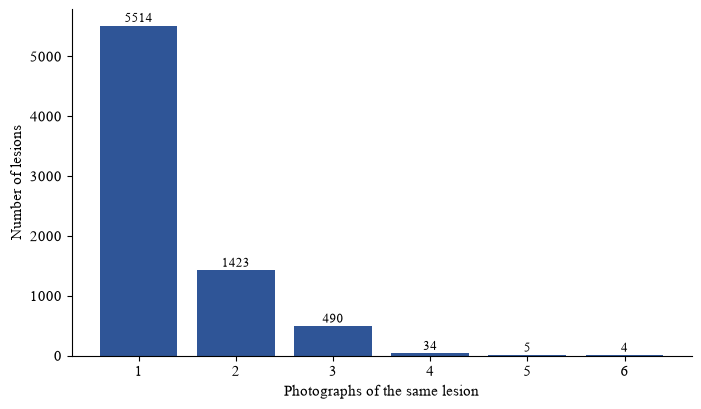

Lesions with more than one photograph: 1956 of 7470 (26.2%)
Most photographs of a single lesion: 6


In [17]:
per_lesion = df.groupby("lesion_id").size()
dist = per_lesion.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(dist.index.astype(str), dist.values, color="#2F5597")

for i, v in enumerate(dist.values):
    ax.text(i, v + 60, str(v), ha="center", fontsize=9)

ax.set_xlabel("Photographs of the same lesion")
ax.set_ylabel("Number of lesions")
ax.spines[["top", "right"]].set_visible(False)
plt.savefig("results/figures/fig03_photos_per_lesion.png")
plt.show()

multi = (per_lesion > 1).sum()
print(f"Lesions with more than one photograph: {multi} of {len(per_lesion)} "
      f"({multi/len(per_lesion)*100:.1f}%)")
print(f"Most photographs of a single lesion: {per_lesion.max()}")

In [18]:
tmp = df.copy()
tmp["n_photos"] = tmp.groupby("lesion_id").lesion_id.transform("size")
per_les = tmp.groupby("lesion_id").agg(dx=("dx", "first"),
                                       n=("n_photos", "first"))

tbl = per_les.groupby("dx").agg(
    lesions=("n", "size"),
    images=("n", "sum"),
    mean_photos=("n", "mean"),
    max_photos=("n", "max"),
)
tbl["multi_photo_lesions"] = per_les[per_les.n > 1].groupby("dx").size()
tbl["multi_photo_pct"] = (tbl.multi_photo_lesions / tbl.lesions * 100)
tbl = tbl.round(2).sort_values("multi_photo_pct", ascending=False)
print(tbl)

       lesions  images  mean_photos  max_photos  multi_photo_lesions  \
dx                                                                     
mel        614    1113         1.81           6                  384   
df          73     115         1.58           3                   34   
bcc        327     514         1.57           4                  152   
bkl        727    1099         1.51           6                  287   
vasc        98     142         1.45           4                   34   
akiec      228     327         1.43           4                   77   
nv        5403    6705         1.24           6                  988   

       multi_photo_pct  
dx                      
mel              62.54  
df               46.58  
bcc              46.48  
bkl              39.48  
vasc             34.69  
akiec            33.77  
nv               18.29  


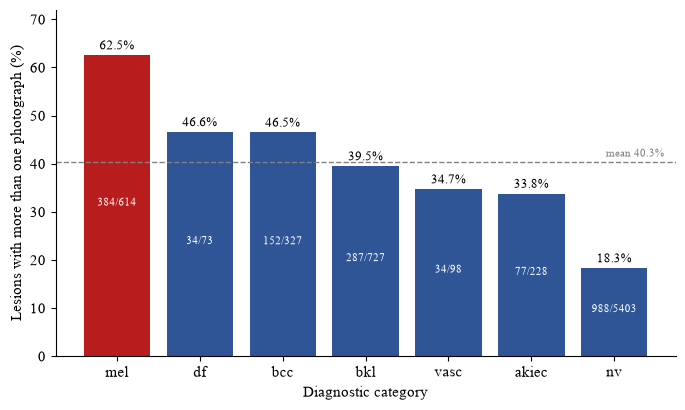

In [20]:
order = tbl.index                       # already sorted, mel first
vals = tbl.multi_photo_pct.values

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#B91C1C" if c == "mel" else "#2F5597" for c in order]
ax.bar(order, vals, color=colors)

for i, (v, n, tot) in enumerate(zip(vals, tbl.multi_photo_lesions, tbl.lesions)):
    ax.text(i, v + 1.2, f"{v:.1f}%", ha="center", fontsize=9)
    ax.text(i, v / 2, f"{n}/{tot}", ha="center", fontsize=8, color="white")

ax.axhline(vals.mean(), ls="--", lw=1, color="grey")
ax.text(len(order) - 0.4, vals.mean() + 1.2, f"mean {vals.mean():.1f}%",
        fontsize=8, color="grey", ha="right")

ax.set_xlabel("Diagnostic category")
ax.set_ylabel("Lesions with more than one photograph (%)")
ax.set_ylim(0, 72)
ax.spines[["top", "right"]].set_visible(False)

plt.savefig("results/figures/fig04_duplication_by_class.png")
plt.show()

[data] indexed 10015 images under data\raw\HAM10000\images


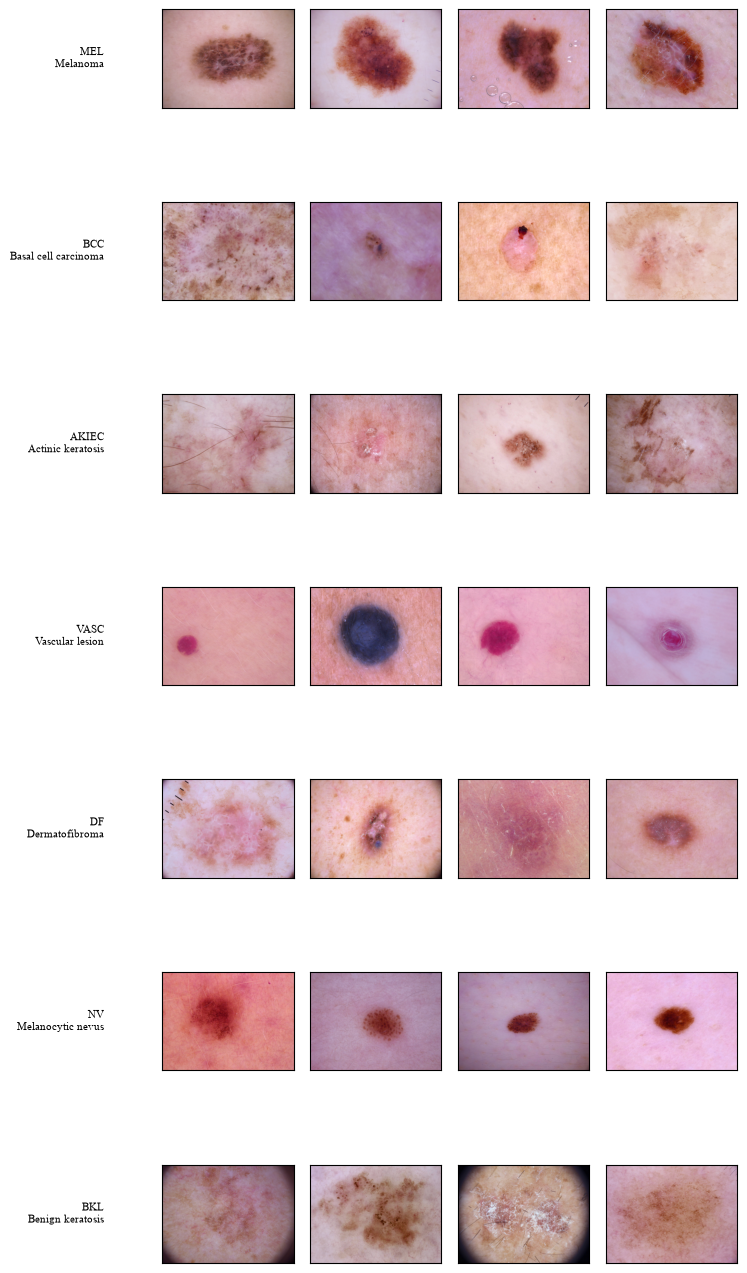

In [21]:
from PIL import Image
from src.data import build_image_index

index = build_image_index("data/raw/HAM10000/images")

CLASS_NAMES = {
    "akiec": "Actinic keratosis", "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis", "df": "Dermatofibroma",
    "mel": "Melanoma", "nv": "Melanocytic nevus", "vasc": "Vascular lesion",
}
show = ["mel", "bcc", "akiec", "vasc", "df", "nv", "bkl"]
n_per = 4

# Only training images: val and test must never be inspected by eye
train_df = pd.read_csv("data/splits/train.csv")

fig, axes = plt.subplots(len(show), n_per, figsize=(n_per * 1.9, len(show) * 2.0))
for r, cls in enumerate(show):
    picks = train_df[train_df.dx == cls].sample(n_per, random_state=42)
    for c, (_, row) in enumerate(picks.iterrows()):
        ax = axes[r, c]
        ax.imshow(Image.open(index[row.image_id]).convert("RGB"))
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(f"{cls.upper()}\n{CLASS_NAMES[cls]}",
                          fontsize=8, rotation=0, ha="right", va="center", labelpad=42)

plt.tight_layout()
plt.savefig("results/figures/fig05_real_samples.png")
plt.show()

In [2]:
import os
os.chdir(r"D:\thesis")
print("working directory:", os.getcwd())

working directory: D:\thesis


In [3]:
import os
os.chdir(r"D:\thesis")

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path

mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman"],
    "font.size": 11, "savefig.dpi": 300, "figure.dpi": 100,
    "savefig.bbox": "tight",
})

df = pd.read_csv("data/raw/HAM10000/HAM10000_metadata.csv")
tr = pd.read_csv("data/splits/train.csv")
va = pd.read_csv("data/splits/val.csv")
te = pd.read_csv("data/splits/test.csv")
counts = df.dx.value_counts()

print(os.getcwd())
print(len(tr), len(va), len(te))

D:\thesis
6981 1532 1502


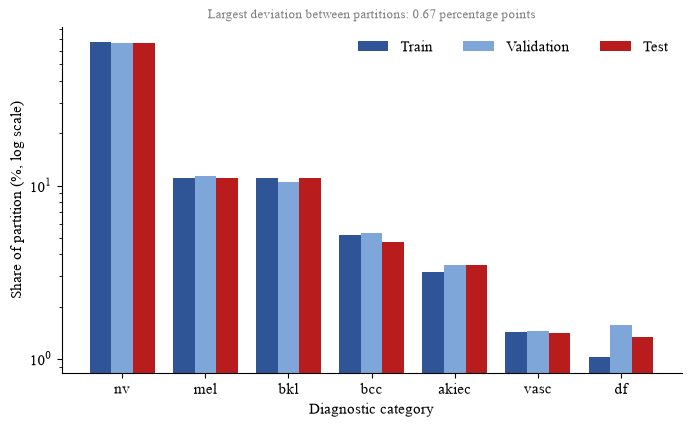

       Train  Validation   Test
dx                             
nv     67.08       66.45  66.84
mel    11.07       11.29  11.12
bkl    11.06       10.44  11.12
bcc     5.17        5.35   4.73
akiec   3.18        3.46   3.46
vasc    1.42        1.44   1.40
df      1.02        1.57   1.33


In [4]:
parts = {"Train": tr, "Validation": va, "Test": te}
order = counts.index                      # nv, mel, bkl, bcc, akiec, vasc, df

pct = pd.DataFrame({
    name: p.dx.value_counts(normalize=True)[order] * 100
    for name, p in parts.items()
})

x = np.arange(len(order))
w = 0.26

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (name, col) in enumerate(zip(pct.columns, ["#2F5597", "#7FA6D9", "#B91C1C"])):
    ax.bar(x + (i - 1) * w, pct[name], w, label=name, color=col)

ax.set_yscale("log")
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_xlabel("Diagnostic category")
ax.set_ylabel("Share of partition (%, log scale)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncol=3)

gap = (pct.max(axis=1) - pct.min(axis=1)).max()
ax.set_title(f"Largest deviation between partitions: {gap:.2f} percentage points",
             fontsize=9, color="grey")

plt.savefig("results/figures/fig06_split_composition.png")
plt.show()
print(pct.round(2))